Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Imagens — Avaliação M2

# Filtragem passa-baixa na frequência × Otsu, k-means e Canny em caracteres com falhas

**Integrantes:** Gustavo Corrêa de Mello, Heloisa Cavalcante Born e João Paulo Jorge Aimi

**Objetivo:** medir quanto os passa-baixa ideal, Butterworth e gaussiano reduzem as falhas nos traços, aplicando Otsu, k-means e Canny antes e depois da filtragem, nos mesmos recortes, e verificar apagamento de traços, união de letras e preenchimento de espaços internos.

**Repositório:** https://github.com/mello745/trab-m2-pdi — o notebook importa o código de `src/`; execute-o a partir do repositório clonado (ver README).

Sem operações morfológicas. A rotulação de componentes conexos só **mede** os resultados.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from inspect import getsource
from IPython.display import Code

from src.utils import RECORTES, carregar_imagem, preparar, recortar, mostrar, painel_recortes, grafico_metricas
from src.filtros import FILTROS, createPB, filtrar_pb, para_uint8
from src.filtros import convolve2d, gaussian_kernel
from src.segmentacao import (otsu_threshold, segmentar_otsu, kmeans_segmentation, segmentar_kmeans,
                             sobel_filters, non_max_suppression, double_threshold, hysteresis, segmentar_canny)
from src.metricas import (contagens_esperadas, areas_buracos, espessura, metricas_mascara, metricas_canny,
                          escore, escore_canny, psnr, ssim)

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.precision', 3)
pd.set_option('display.width', 160)

DATA = RAIZ / 'data'
RESULTADOS = RAIZ / 'resultados'
RESULTADOS.mkdir(exist_ok=True)

def salvar(fig, nome):
    fig.savefig(RESULTADOS / f'{nome}.png', bbox_inches='tight')

def ver(*funcoes):
    """Mostra no notebook o código das funções implementadas em src/."""
    return Code('\n'.join(getsource(f) for f in funcoes), language='python')

## 1. Imagem, recortes e referência esperada

Imagem `Fig0419(a)` (Gonzalez & Woods, 3ª ed.), salva em `data/texto_falhas.tif`: texto com falhas de 1 e 2 px.

In [2]:
bruta = carregar_imagem(DATA / 'texto_falhas.tif')
print('tamanho:', bruta.shape, '| tipo:', bruta.dtype, '| valores presentes:', np.unique(bruta))
print('moldura preta de 1 px?', (bruta[0] == 0).all() and (bruta[-1] == 0).all()
      and (bruta[:, 0] == 0).all() and (bruta[:, -1] == 0).all())

tamanho: (444, 508) | tipo: uint8 | valores presentes: [  0 255]
moldura preta de 1 px? True


Pré-processamento (`preparar`):

* a imagem já é **binária** — sem filtragem, Otsu e k-means apenas a reproduzem;
* a **moldura preta de 1 px** é recortada (viraria um componente gigante e geraria ringing);
* as intensidades são **invertidas** (texto = 255), para que o preenchimento com zeros da FFT estenda o fundo.

`T0` é a máscara do texto original, usada como referência.

imagem de trabalho: 442 x 506 | fração de pixels de texto: 0.0709


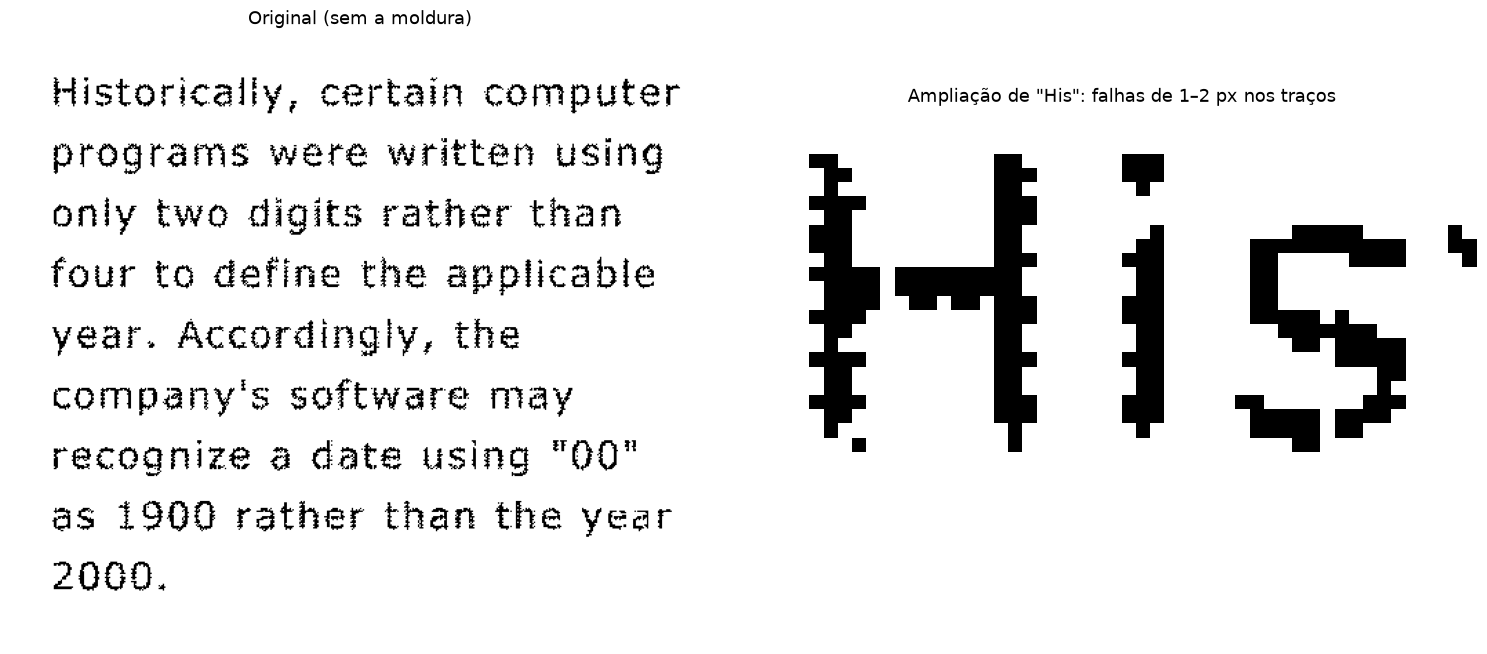

In [3]:
img, T0, f = preparar(bruta)
M, N = f.shape
print(f'imagem de trabalho: {M} x {N} | fração de pixels de texto: {T0.mean():.4f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.1, 1]})
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Original (sem a moldura)')
ax[1].imshow(img[29:61, 28:78], cmap='gray', interpolation='nearest')
ax[1].set_title('Ampliação de "His": falhas de 1–2 px nos traços')
for a in ax: a.axis('off')
plt.tight_layout(); salvar(fig, '01_original'); plt.show()

### Recortes de comparação

| Recorte | Conteúdo | Testa |
|---|---|---|
| A | `Historically,` | união (`ll`, `ic`) e apagamento (pingos, vírgula) |
| B | `programs` | espaços internos de `g`, `o`, `a` |
| C | `company's` | preenchimento e o apóstrofo |
| D | `"00"` | aspas coladas nos zeros e buracos grandes |

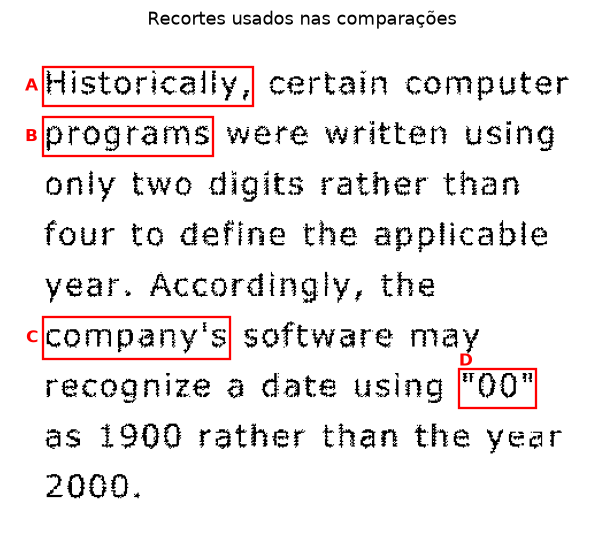

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(img, cmap='gray')
for nome, (a, b, c, d) in RECORTES.items():
    ax.add_patch(plt.Rectangle((c, a), d - c, b - a, fill=False, ec='red', lw=1.5))
    if c < 50:   # recortes na margem esquerda: rótulo à esquerda do retângulo
        ax.text(c - 4, (a + b) / 2, nome.split(':')[0], color='red', fontsize=11, weight='bold', ha='right', va='center')
    else:
        ax.text(c, a - 3, nome.split(':')[0], color='red', fontsize=11, weight='bold')
ax.set_title('Recortes usados nas comparações'); ax.axis('off')
salvar(fig, '02_recortes'); plt.show()

### Referência esperada

Não há imagem limpa, mas o texto é conhecido: um componente por caractere (`i`, `j` e `"` contam 2) e um buraco em `a b d e g o p q A D O P Q R 0 4 6 9` (`B` e `8` têm 2).

In [5]:
C_ESP, H_ESP = contagens_esperadas()
print(f'componentes esperados: {C_ESP} | buracos esperados: {H_ESP}')

componentes esperados: 205 | buracos esperados: 72


## 2. Filtros passa-baixa no domínio da frequência

| Filtro | $H(u,v)$ |
|---|---|
| Ideal | $1$ se $D \le D_0$, senão $0$ — corte abrupto, **ringing** |
| Butterworth | $1/(1+[D/D_0]^{2n})$ — ringing cresce com $n$ |
| Gaussiano | $e^{-D^2/2D_0^2}$ — **sem ringing** |

Preenchimento com zeros ($P=2M$, $Q=2N$, então $D_0$ é medido em 884×1012), **parte real** da inversa (a magnitude rebateria o ringing negativo) e recorte em [0, 255].

In [6]:
ver(createPB, filtrar_pb, para_uint8)

def createPB(shape, center, radius, lpType=2, n=2):
    """Máscara H(u,v) passa-baixa.

    lpType: 0 = ideal, 1 = Butterworth (ordem n), 2 = gaussiano. radius = D0.
    D(u,v) é a distância de (u,v) até `center` = (coluna, linha).
    """
    rows, cols = shape[:2]
    r, c = np.mgrid[0:rows, 0:cols].astype(np.float64)
    c -= center[0]
    r -= center[1]
    d = np.sqrt(np.power(c, 2) + np.power(r, 2))                # D(u,v)
    if lpType == 0:      # ideal: 1 dentro do raio D0, 0 fora
        return (d <= radius).astype(np.float64)
    if lpType == 1:      # Butterworth: 1 / (1 + (D/D0)^2n)
        return 1 / (1 + np.power(d / radius, 2 * n))
    return np.exp(-np.power(d, 2) / (2 * radius ** 2))         # gaussiano: e^(-D²/2D0²)

def filtrar_pb(f, lpType, D0, n=2):
    """Aplica o passa-baixa e devolve a imagem filtrada (float) do tamanho de `f`.

    Preenchimento com zeros (P=2M, Q=2N), como nos slides, para que F·H seja
    convolução linear e não circular. Volta ao espaço pela parte REAL: a magnitude
    rebateria os valores negativos do ringing e criaria texto falso.
    """
    M, N = f.shape
    P, Q = 2 * M, 2 * N
    fp = np.zeros((P, Q))
    fp[:M, :N] = f
    F = np.fft.fftshift(np.fft.fft2(fp))                        # espectro centralizado
    H = createPB((P, Q), center=(Q // 2, P // 2), radius=D0, lpType=lpType, n=n)
    g = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))          # G = F·H e volta ao espaço
    return g[:M, :N]

def para_uint8(g):
    """Recorta em [0, 255] (sem normalizar min-max, para manter a mesma escala entre filtros)."""
    return np.clip(np.round(g), 0, 255).astype(np.uint8)

### Visualizando os filtros

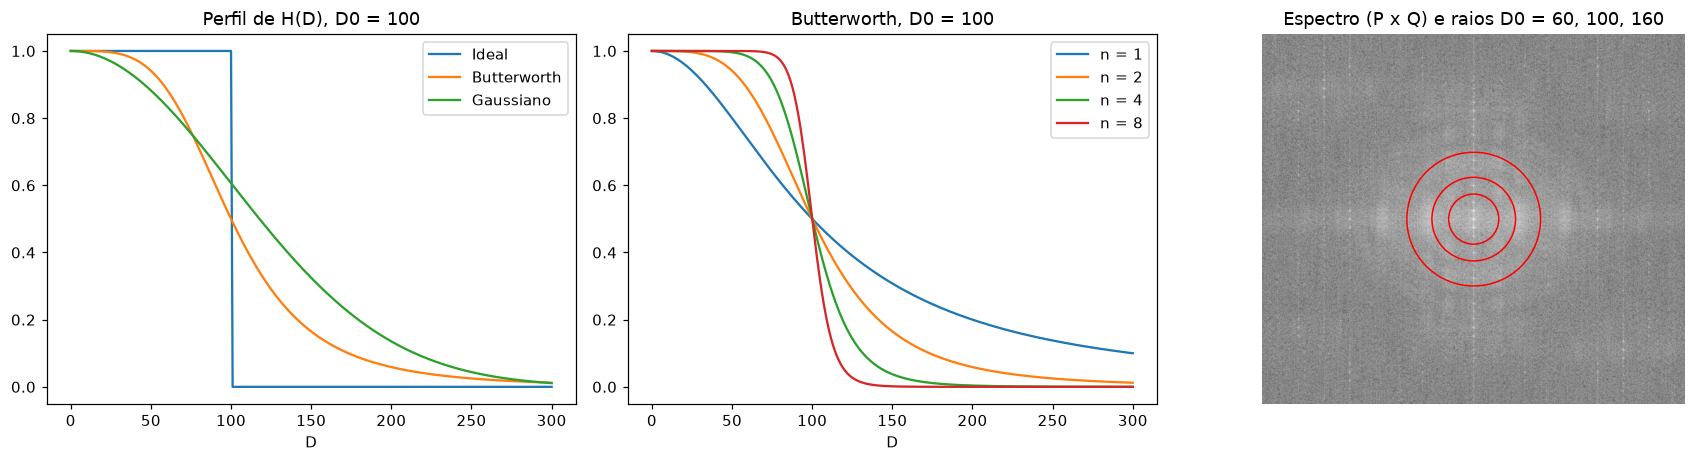

In [7]:
D = np.arange(301)                     # distância ao centro, em pixels do espectro
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for tp, nome in FILTROS.items():
    ax[0].plot(D, createPB((1, 301), (0, 0), 100, tp, 2)[0], label=nome)
ax[0].set_title('Perfil de H(D), D0 = 100'); ax[0].set_xlabel('D'); ax[0].legend()
for n in (1, 2, 4, 8):
    ax[1].plot(D, createPB((1, 301), (0, 0), 100, 1, n)[0], label=f'n = {n}')
ax[1].set_title('Butterworth, D0 = 100'); ax[1].set_xlabel('D'); ax[1].legend()

P, Q = 2 * M, 2 * N
fp = np.zeros((P, Q)); fp[:M, :N] = f
espectro = 20 * np.log(np.abs(np.fft.fftshift(np.fft.fft2(fp))) + 1)
ax[2].imshow(espectro, cmap='gray')
for D0 in (60, 100, 160):
    ax[2].add_patch(plt.Circle((Q // 2, P // 2), D0, fill=False, ec='red', lw=1))
ax[2].set_title('Espectro (P x Q) e raios D0 = 60, 100, 160'); ax[2].axis('off')
plt.tight_layout(); salvar(fig, '03_filtros'); plt.show()

### Efeito dos filtros no recorte A

Ideal: anéis. Butterworth: poucos. Gaussiano: nenhum. Quanto menor $D_0$, mais o traço se espalha.

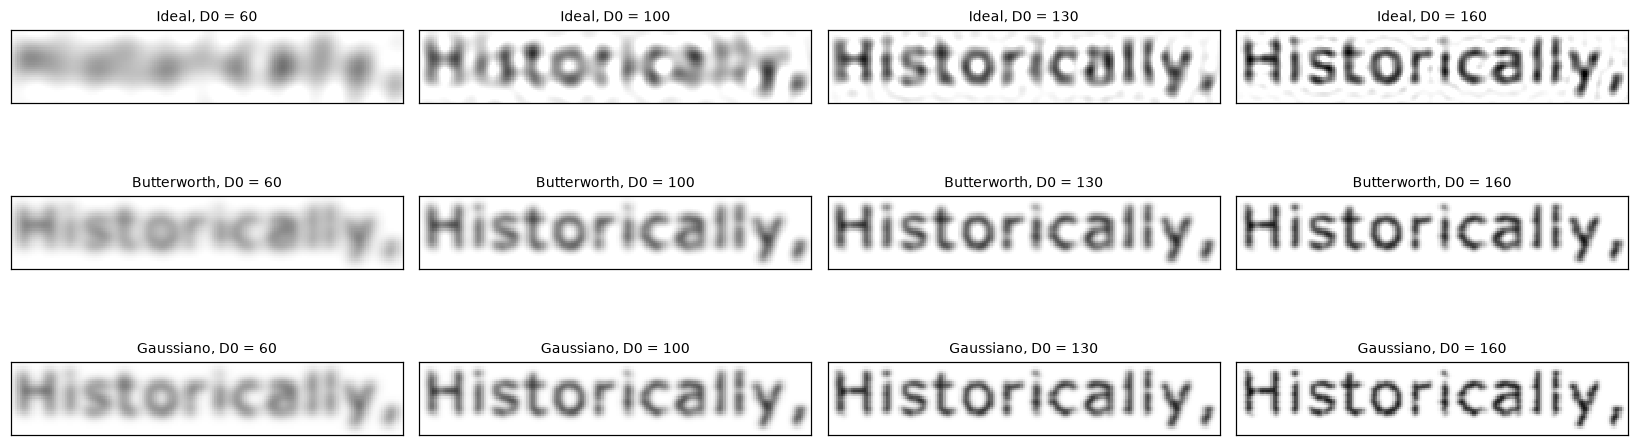

In [8]:
fig, ax = plt.subplots(3, 4, figsize=(15, 5.2))
for i, (tp, nome) in enumerate(FILTROS.items()):
    for j, D0 in enumerate((60, 100, 130, 160)):
        g = para_uint8(filtrar_pb(f, tp, D0))
        mostrar(ax[i, j], recortar(g, 'A: Historically,'))
        ax[i, j].set_title(f'{nome}, D0 = {D0}', fontsize=9)
plt.tight_layout(); salvar(fig, '04_filtradas_recorteA'); plt.show()

## 3. Métodos de segmentação

* **Otsu** (implementação da aula): texto é $I > t$. Com `>=`, a imagem binária original vira toda texto ($t = 0$).
* **k-means** (implementação da aula) com centróides iniciais espaçados, e não sorteados (93% dos pixels valem 0). Texto = cluster de maior centróide. **k=2** equivale ao Otsu; **k=3** mantém só o cluster mais claro (traço mais fino).
* **Canny** (implementação da aula): Sobel, supressão de não-máximos, limiar duplo ($T_1=30$, $T_2=100$, padrão da aula) e histerese. **Sem** a suavização gaussiana inicial: o passa-baixa faz esse papel. Uma alteração: na supressão de não-máximos, `>` para um dos vizinhos — numa imagem binária os dois pixels da transição empatam, e com `>=` nos dois a borda sai com 2 px e encobre as falhas.

Funções prontas usadas: só `numpy.fft` (FFT), `cv2.imread` e a rotulação de componentes conexos nas métricas.

In [9]:
ver(otsu_threshold, segmentar_otsu, kmeans_segmentation, segmentar_kmeans)

def otsu_threshold(img):
    """Limiar t que maximiza a variância entre classes (implementação da aula)."""
    img = img.astype(np.uint8)
    hist = np.bincount(img.ravel(), minlength=256)
    prob = hist / img.size

    cumulative_prob = np.cumsum(prob)
    cumulative_mean = np.cumsum(prob * np.arange(256))
    global_mean = cumulative_mean[-1]

    numerator = (global_mean * cumulative_prob - cumulative_mean) ** 2
    denominator = cumulative_prob * (1 - cumulative_prob)
    denominator = np.where(denominator == 0, 1e-10, denominator)

    return int(np.argmax(numerator / denominator))

def segmentar_otsu(img):
    """Máscara de texto pelo Otsu. Devolve (mascara, t).

    A classe 1 do Otsu é {0..t}, então texto é `img > t`. Com `>=` (material da aula),
    a imagem binária original vira toda texto: os limiares empatam e o argmax dá t = 0.
    """
    t = otsu_threshold(img)
    return img > t, t

def kmeans_segmentation(img, k=2, max_iter=100, tol=1e-4):
    """k-means nas intensidades (implementação da aula). Devolve (rotulos, centroides).

    Centróides iniciais espaçados entre o mínimo e o máximo, em vez de sorteados:
    com ~93% dos pixels iguais a 0, o sorteio quase sempre repetiria centróides.
    """
    pixels = img.reshape(-1, 1).astype(np.float64)
    centroids = np.linspace(pixels.min(), pixels.max(), k).reshape(k, 1)

    for _ in range(max_iter):
        labels = np.argmin(np.abs(pixels - centroids.T), axis=1)      # atribuição
        new_centroids = centroids.copy()
        for cluster in range(k):                                       # atualização
            cluster_pixels = pixels[labels == cluster]
            if len(cluster_pixels) > 0:
                new_centroids[cluster] = cluster_pixels.mean(axis=0)
        shift = np.linalg.norm(new_centroids - centroids)              # convergência
        centroids = new_centroids
        if shift < tol:
            break

    labels = np.argmin(np.abs(pixels - centroids.T), axis=1)
    return labels.reshape(img.shape), centroids.ravel()

def segmentar_kmeans(img, k):
    """Máscara de texto = cluster de maior centróide. Devolve (mascara, centroides)."""
    labels, centroids = kmeans_segmentation(img, k)
    return labels == np.argmax(centroids), centroids

In [10]:
ver(convolve2d, sobel_filters, non_max_suppression, double_threshold, hysteresis, segmentar_canny)

def convolve2d(image, kernel):
    """`convolve2d` da aula (correlação com preenchimento de zeros), sem os laços:
    cada pixel de saída é a soma da janela vizinha multiplicada pelo kernel."""
    kh, kw = kernel.shape
    padded = np.pad(image.astype(np.float64), ((kh // 2, kh // 2), (kw // 2, kw // 2)), mode='constant')
    janelas = np.lib.stride_tricks.sliding_window_view(padded, (kh, kw))
    return np.einsum('ijkl,kl->ij', janelas, kernel)

def sobel_filters(image):
    """Gradiente de Sobel; magnitude normalizada para [0, 255] (aula)."""
    Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    Ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])
    Gx = convolve2d(image, Kx)
    Gy = convolve2d(image, Ky)
    magnitude = np.hypot(Gx, Gy)
    magnitude = magnitude / (magnitude.max() + 1e-10) * 255
    direction = np.arctan2(Gy, Gx)
    return magnitude, direction

def non_max_suppression(magnitude, direction):
    """Supressão de não-máximos da aula, vetorizada: mantém o pixel só se ele for o
    máximo entre os dois vizinhos na direção do gradiente (4 faixas de ângulo).

    Alteração: `>` para o vizinho q e `>=` para r (na aula, `>=` nos dois). Numa imagem
    binária os dois pixels da transição têm o mesmo gradiente; com `>=` nos dois, ambos
    ficam, a borda sai com 2 px e encobre as falhas de 1–2 px. O desempate deixa 1 px.
    """
    angle = np.degrees(direction)
    angle[angle < 0] += 180
    m, a = magnitude, angle[1:-1, 1:-1]
    centro = m[1:-1, 1:-1]
    vizinhos = [(m[1:-1, 2:], m[1:-1, :-2]),    # 0°:   (i, j+1) e (i, j-1)
                (m[2:, :-2], m[:-2, 2:]),       # 45°:  (i+1, j-1) e (i-1, j+1)
                (m[2:, 1:-1], m[:-2, 1:-1]),    # 90°:  (i+1, j) e (i-1, j)
                (m[:-2, :-2], m[2:, 2:])]       # 135°: (i-1, j-1) e (i+1, j+1)
    faixa = np.select([(a < 22.5) | (a >= 157.5), a < 67.5, a < 112.5], [0, 1, 2], 3)
    q = np.choose(faixa, [v[0] for v in vizinhos])
    r = np.choose(faixa, [v[1] for v in vizinhos])
    out = np.zeros(m.shape, dtype=np.float32)
    out[1:-1, 1:-1] = np.where((centro > q) & (centro >= r), centro, 0)
    return out

def double_threshold(image, T1=30, T2=100):
    """Pixels fortes (>= T2) e fracos (entre T1 e T2), como na aula."""
    weak, strong = 75, 255
    result = np.zeros(image.shape, dtype=np.uint8)
    result[image >= T2] = strong
    result[(image >= T1) & (image < T2)] = weak
    return result, weak, strong

def hysteresis(image, weak=75, strong=255):
    """Histerese da aula: o pixel fraco vira forte se tiver um vizinho forte, senão é descartado.
    Percorre só os pixels fracos, na mesma ordem (linha a linha) do laço original."""
    h, w = image.shape
    out = image.copy()
    for i, j in np.argwhere(out[1:h-1, 1:w-1] == weak) + 1:
        out[i, j] = strong if np.any(out[i-1:i+2, j-1:j+2] == strong) else 0
    return out

def segmentar_canny(img, T1=30, T2=100):
    """Canny da aula (Sobel, supressão de não-máximos, limiar duplo e histerese), sem a
    suavização gaussiana inicial: nos experimentos, o passa-baixa faz esse papel.
    Devolve o mapa de bordas booleano."""
    magnitude, direction = sobel_filters(img)
    nms = non_max_suppression(magnitude, direction)
    limiar, weak, strong = double_threshold(nms, T1, T2)
    return hysteresis(limiar, weak, strong) == strong

## 4. Métricas

| Métrica | Mede | Ideal |
|---|---|---|
| `componentes` | quebras (↑) e uniões (↓) | 205 |
| `buracos_legit` | buracos > 3 px; cai com **preenchimento** | 72 |
| `furos_falha` | buracos de 1–3 px = **falhas** | 0 |
| `unioes` | componentes com largura > 28 px | 0 |
| `preservacao_%` | texto original mantido; < 100 = **apagamento** | 100 |
| `espessura_px` | moda das corridas horizontais | 2 |

**Escore** (menor é melhor): $\frac{|C-205|}{205} + \frac{|H-72|}{72} + \frac{\text{furos}}{165} + \frac{\text{uniões}}{205} + (1-\frac{\text{preservação}}{100})$

**Canny:** `segmentos`, `pontas_soltas` (contornos abertos) e `pixels_borda`; escore $= \frac{|\text{segmentos}-277|}{277} + \frac{\text{pontas}}{763}$ (763 = pontas soltas sem filtragem).

**PSNR / SSIM** (slides) comparam com a imagem com falhas: medem quanto o filtro **alterou**, não quanto corrigiu.

In [11]:
ver(areas_buracos, espessura, metricas_mascara, metricas_canny, escore, escore_canny, psnr, ssim)

def areas_buracos(mask):
    """Áreas das regiões de fundo que não tocam a borda (vizinhança-4 no fundo)."""
    n, lab, st, _ = cv2.connectedComponentsWithStats((~mask).astype(np.uint8), connectivity=4)
    borda = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])))
    return np.array([st[j, cv2.CC_STAT_AREA] for j in range(1, n) if j not in borda])

def espessura(mask):
    """Moda do comprimento das corridas horizontais de texto."""
    corridas = []
    for linha in mask.astype(np.int8):
        d = np.diff(np.concatenate([[0], linha, [0]]))
        corridas.extend(np.where(d == -1)[0] - np.where(d == 1)[0])
    return int(np.bincount(corridas).argmax())

def metricas_mascara(mask, ref):
    """Métricas estruturais de uma máscara de texto; `ref` = máscara do texto original."""
    n, _, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    buracos = areas_buracos(mask)
    return {
        'componentes': n - 1,
        'buracos_legit': int((buracos > AREA_FALHA).sum()),
        'furos_falha': int((buracos <= AREA_FALHA).sum()),
        'unioes': int((st[1:, cv2.CC_STAT_WIDTH] > LARGURA_MAX).sum()),
        'preservacao_%': 100 * (mask & ref).sum() / ref.sum(),
        'acrescimo_%': 100 * (mask & ~ref).sum() / ref.sum(),
        'espessura_px': espessura(mask),
    }

def metricas_canny(bordas):
    """Segmentos de borda, pontas soltas (pixel com 1 vizinho = contorno aberto) e total de pixels."""
    n, _ = cv2.connectedComponents(bordas.astype(np.uint8), connectivity=8)
    vizinhos = convolve2d(bordas, np.ones((3, 3))) - bordas      # vizinhos de borda na janela 3x3
    return {
        'segmentos': n - 1,
        'pontas_soltas': int((bordas & (vizinhos == 1)).sum()),
        'pixels_borda': int(bordas.sum()),
    }

def escore(m, c_esp, h_esp, furos_orig):
    """Soma dos erros relativos das métricas estruturais (menor é melhor)."""
    return (abs(m['componentes'] - c_esp) / c_esp + abs(m['buracos_legit'] - h_esp) / h_esp
            + m['furos_falha'] / furos_orig + m['unioes'] / c_esp + (1 - m['preservacao_%'] / 100))

def escore_canny(m, contornos_esp, pontas_orig):
    """Erro relativo no nº de contornos + pontas soltas relativas ao original (menor é melhor)."""
    return abs(m['segmentos'] - contornos_esp) / contornos_esp + m['pontas_soltas'] / pontas_orig

def psnr(a, b, L=255):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(L ** 2 / mse)

def ssim(a, b, L=255):
    """SSIM médio com janela gaussiana 11x11, sigma 1.5 (Wang et al.), via convolve2d."""
    a = a.astype(np.float64); b = b.astype(np.float64)
    C1, C2 = (0.01 * L) ** 2, (0.03 * L) ** 2
    janela = lambda x: convolve2d(x, gaussian_kernel(11, 1.5))   # médias locais
    mu_a, mu_b = janela(a), janela(b)
    var_a = janela(a * a) - mu_a ** 2
    var_b = janela(b * b) - mu_b ** 2
    cov = janela(a * b) - mu_a * mu_b
    mapa = ((2 * mu_a * mu_b + C1) * (2 * cov + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (var_a + var_b + C2))
    return mapa.mean()

## 5. Métodos sem filtragem (linha de base)

In [12]:
u0 = f.astype(np.uint8)
otsu0, t0 = segmentar_otsu(u0)
km2_0, c2_0 = segmentar_kmeans(u0, 2)
km3_0, c3_0 = segmentar_kmeans(u0, 3)
canny0 = segmentar_canny(u0)
print(f'Otsu: t = {t0} | k-means k=2: centróides {np.round(c2_0)} | k=3: {np.round(c3_0)}')

FUROS_ORIG = metricas_mascara(T0, T0)['furos_falha']
CONTORNOS_ESP = C_ESP + H_ESP
PONTAS_ORIG = metricas_canny(canny0)['pontas_soltas']

base = pd.DataFrame({nome: metricas_mascara(m, T0)
                     for nome, m in [('Otsu', otsu0), ('k-means k=2', km2_0), ('k-means k=3', km3_0)]}).T
base.loc['esperado', ['componentes', 'buracos_legit', 'furos_falha', 'unioes']] = [C_ESP, H_ESP, 0, 0]
display(base)
print('Canny sem filtragem:', metricas_canny(canny0),
      f'| contornos esperados ≈ {CONTORNOS_ESP}, pontas soltas esperadas = 0')

Otsu: t = 0 | k-means k=2: centróides [  0. 255.] | k=3: [  0. 128. 255.]


,componentes,buracos_legit,furos_falha,unioes,preservacao_%,acrescimo_%,espessura_px
Otsu,265.0,43.0,165.0,0.0,100.0,0.0,2.0
k-means k=2,265.0,43.0,165.0,0.0,100.0,0.0,2.0
k-means k=3,265.0,43.0,165.0,0.0,100.0,0.0,2.0
esperado,205.0,72.0,0.0,0.0,NaN,NaN,NaN


Canny sem filtragem: {'segmentos': 406, 'pontas_soltas': 763, 'pixels_borda': 14528} | contornos esperados ≈ 277, pontas soltas esperadas = 0


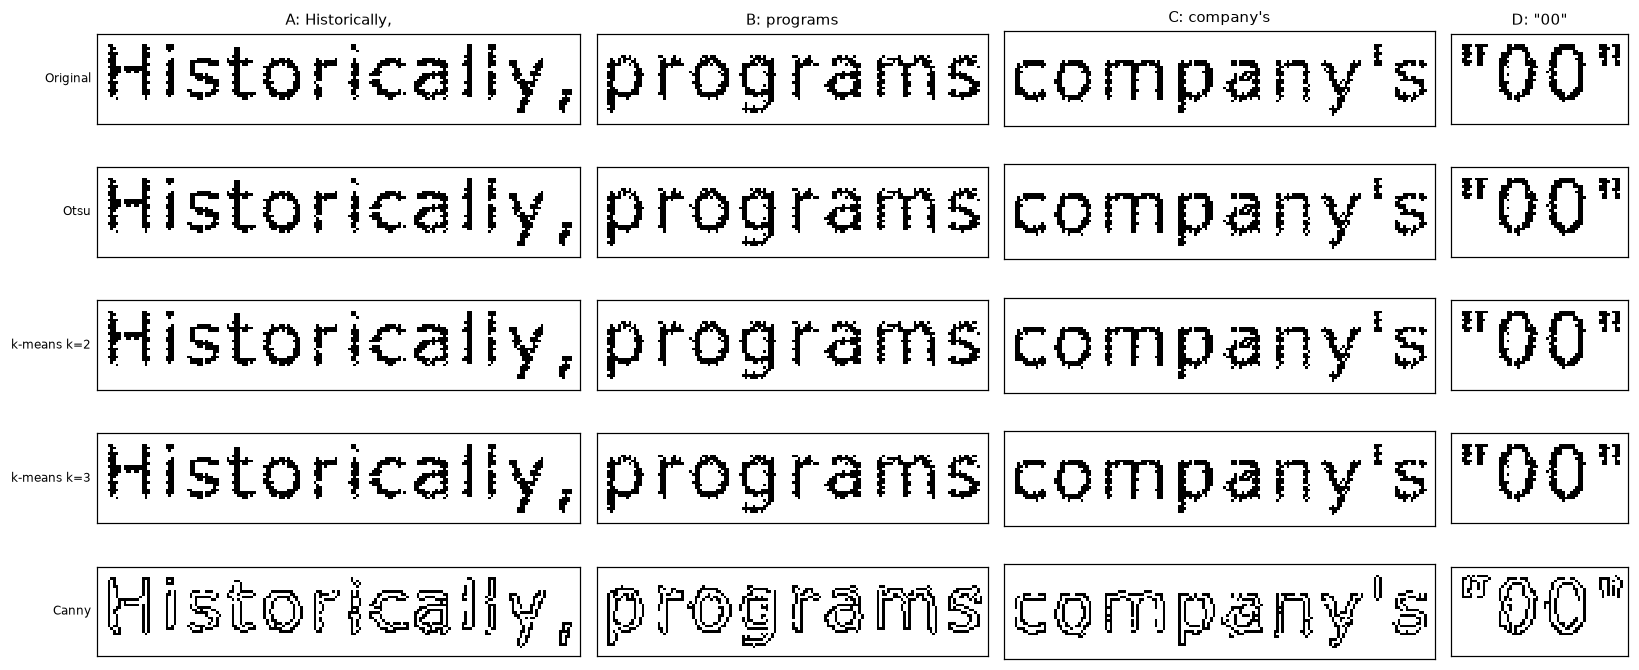

In [13]:
fig = painel_recortes([('Original', u0), ('Otsu', otsu0), ('k-means k=2', km2_0),
                       ('k-means k=3', km3_0), ('Canny', canny0)], altura_linha=1.3)
salvar(fig, '05_baseline'); plt.show()

Sem filtragem, nenhuma falha é corrigida: 265 componentes (205 esperados), 43 buracos (72) e 165 furos. O Canny contorna cada furo: 406 segmentos (≈ 277 esperados) e 763 pontas soltas.

## 6. Métodos após a filtragem

Ideal, Butterworth ($n=2$) e gaussiano com $D_0 \in \{60, 80, 100, 130, 160, 200\}$, cada um seguido dos quatro métodos.

In [14]:
D0S = [60, 80, 100, 130, 160, 200]
METODOS_MASCARA = ['Otsu', 'k-means k=2', 'k-means k=3']

def processar(u):
    otsu, t = segmentar_otsu(u)
    km2, c2 = segmentar_kmeans(u, 2)
    km3, c3 = segmentar_kmeans(u, 3)
    return {'img': u, 'Otsu': otsu, 'k-means k=2': km2, 'k-means k=3': km3,
            'Canny': segmentar_canny(u), 't_otsu': t, 'c_km2': c2, 'c_km3': c3}

resultados = {('Sem filtro', 0, 0): processar(u0)}
for tp, nome in FILTROS.items():
    for D0 in D0S:
        resultados[(nome, D0, 2)] = processar(para_uint8(filtrar_pb(f, tp, D0)))

linhas_mask, linhas_canny, linhas_filtro = [], [], []
for (filtro, D0, n), r in resultados.items():
    chave = {'filtro': filtro, 'D0': D0, 'n': n}
    linhas_filtro.append({**chave, 'PSNR_dB': psnr(r['img'], u0), 'SSIM': ssim(r['img'], u0),
                          't_otsu': r['t_otsu'], 'limiar_km2': r['c_km2'].mean()})
    for met in METODOS_MASCARA:
        linhas_mask.append({**chave, 'metodo': met, **metricas_mascara(r[met], T0)})
    linhas_canny.append({**chave, 'metodo': 'Canny', **metricas_canny(r['Canny'])})

df_filtro = pd.DataFrame(linhas_filtro)
df_mask = pd.DataFrame(linhas_mask)
df_mask['escore'] = df_mask.apply(lambda m: escore(m, C_ESP, H_ESP, FUROS_ORIG), axis=1)
df_canny = pd.DataFrame(linhas_canny)
df_canny['escore'] = df_canny.apply(lambda m: escore_canny(m, CONTORNOS_ESP, PONTAS_ORIG), axis=1)
df_mask.to_csv(RESULTADOS / 'metricas_otsu_kmeans.csv', index=False)
df_canny.to_csv(RESULTADOS / 'metricas_canny.csv', index=False)
df_filtro.to_csv(RESULTADOS / 'metricas_filtros.csv', index=False)
print(f'{len(resultados)} imagens processadas -> {len(df_mask)} linhas (Otsu/k-means) e {len(df_canny)} (Canny)')

19 imagens processadas -> 57 linhas (Otsu/k-means) e 19 (Canny)


### 6.1 PSNR / SSIM e limiares

`limiar_km2` = ponto médio dos centróides do k-means k=2; coincide com o limiar do Otsu.

In [15]:
display(df_filtro.set_index(['filtro', 'D0']).drop(columns='n'))

PSNR_dB   SSIM  t_otsu  limiar_km2
filtro      D0                                     
Sem filtro  0        inf  1.000       0     127.500
Ideal       60    13.048  0.470      38      38.282
            80    13.366  0.437      42      42.461
            100   13.893  0.428      50      50.305
            130   15.227  0.495      65      65.298
            160   16.143  0.500      74      74.282
            200   16.948  0.612      81      81.747
Butterworth 60    13.493  0.617      36      37.091
            80    14.125  0.678      42      42.535
            100   14.835  0.732      50      50.467
            130   15.870  0.797      60      61.150
            160   16.804  0.845      69      70.158
            200   17.953  0.889      81      81.432
Gaussiano   60    13.870  0.645      38      38.602
            80    14.683  0.716      47      47.523
            100   15.460  0.770      55      55.526
            130   16.536  0.831      65      65.391
            160   17.545  0.873      73      73.452
            200   18.860  0.912      84      84.557

### 6.2 Métricas estruturais (Otsu) e do Canny

Os gráficos de cada métrica em função de $D_0$ estão no relatório.

In [16]:
colunas = ['componentes', 'buracos_legit', 'furos_falha', 'unioes', 'preservacao_%', 'espessura_px', 'escore']
display(df_mask[df_mask.metodo == 'Otsu'].set_index(['filtro', 'D0'])[colunas])

# gráficos das métricas × D0: só salvos em resultados/, usados no relatório
for nome, df, mets, esp in [
        ('06_metricas_a', df_mask, ['componentes', 'buracos_legit', 'furos_falha'],
         {'componentes': C_ESP, 'buracos_legit': H_ESP, 'furos_falha': 0}),
        ('06_metricas_b', df_mask, ['unioes', 'preservacao_%', 'espessura_px'], {'unioes': 0, 'preservacao_%': 100}),
        ('07_metricas_canny', df_canny, ['segmentos', 'pontas_soltas', 'pixels_borda'],
         {'segmentos': CONTORNOS_ESP, 'pontas_soltas': 0})]:
    fig = grafico_metricas(df, mets, esp)
    salvar(fig, nome); plt.close(fig)

componentes  buracos_legit  furos_falha  unioes  preservacao_%  espessura_px  escore
filtro      D0                                                                                       
Sem filtro  0            265             43          165       0        100.000             2   1.695
Ideal       60            42              0            0      36         95.021            11   2.021
            80            61             20            2      39         96.086            10   1.666
            100          108             48            2      37         95.834             6   1.041
            130          193             58            0       0         97.359             5   0.279
            160          200             70            0       0         98.393             5   0.068
            200          203             69            1       0         98.065             4   0.077
Butterworth 60            41             15            1      35         99.269            10   1.776
            80            84             25            7      46         99.553             7   1.514
            100          179             36            1      11         99.521             6   0.691
            130          197             66            6       0         99.458             5   0.164
            160          201             71            0       0         99.338             4   0.040
            200          206             71            0       0         99.105             4   0.028
Gaussiano   60            53             25            5      36         99.679             7   1.603
            80           178             38            3      12         99.609             6   0.685
            100          197             64            6       0         99.483             5   0.192
            130          201             71            1       0         99.332             4   0.046
            160          204             71            0       0         99.401             4   0.025
            200          208             69            2       0         99.571             3   0.073

In [17]:
display(df_canny.pivot_table(index=['filtro', 'D0'], values=['segmentos', 'pontas_soltas', 'pixels_borda', 'escore']))

escore  pixels_borda  pontas_soltas  segmentos
filtro      D0                                                 
Butterworth 60    0.908       12010.0          503.0      346.0
            80    0.273       13441.0          181.0      267.0
            100   0.214       14319.0          147.0      271.0
            130   0.157       14725.0          103.0      271.0
            160   0.187       14892.0          101.0      262.0
            200   0.255       15007.0          109.0      246.0
Gaussiano   60    0.334       13475.0          219.0      290.0
            80    0.182       14507.0          136.0      278.0
            100   0.142       14709.0          103.0      275.0
            130   0.192       14920.0          111.0      264.0
            160   0.253       15025.0          116.0      249.0
            200   0.310       15072.0          129.0      238.0
Ideal       60    0.936        8881.0          502.0      354.0
            80    0.575       10816.0          392.0      294.0
            100   0.406       11973.0          304.0      279.0
            130   0.296       14149.0          209.0      271.0
            160   0.252       15100.0          140.0      258.0
            200   0.262       15302.0          101.0      241.0
Sem filtro  0     1.466       14528.0          763.0      406.0

### 6.3 Ordem do Butterworth ($D_0 = 130$)

In [18]:
D0_N = 130
linhas_n = []
for n in (1, 2, 4, 8):
    r = processar(para_uint8(filtrar_pb(f, 1, D0_N, n)))
    resultados[('Butterworth', D0_N, n)] = r
    for met in METODOS_MASCARA:
        m = metricas_mascara(r[met], T0)
        linhas_n.append({'n': n, 'metodo': met, **m, 'escore': escore(m, C_ESP, H_ESP, FUROS_ORIG)})
    linhas_n.append({'n': n, 'metodo': 'Canny', **metricas_canny(r['Canny'])})
df_n = pd.DataFrame(linhas_n)
display(df_n[df_n.metodo != 'Canny'].dropna(axis=1).set_index(['metodo', 'n']))
display(df_n[df_n.metodo == 'Canny'].dropna(axis=1).set_index(['metodo', 'n']))

,,componentes,buracos_legit,furos_falha,unioes,preservacao_%,acrescimo_%,espessura_px,escore
metodo,n,,,,,,,,
Otsu,1,202.0,71.0,0.0,0.0,99.937,61.471,4.0,0.029
k-means k=2,1,202.0,71.0,0.0,0.0,99.937,61.471,4.0,0.029
k-means k=3,1,222.0,51.0,0.0,0.0,95.222,10.998,3.0,0.422
Otsu,2,197.0,66.0,6.0,0.0,99.458,86.159,5.0,0.164
k-means k=2,2,198.0,66.0,5.0,0.0,99.401,84.457,5.0,0.154
k-means k=3,2,207.0,56.0,0.0,0.0,88.964,25.217,3.0,0.342
Otsu,4,195.0,63.0,2.0,0.0,99.067,95.191,5.0,0.195
k-means k=2,4,195.0,63.0,2.0,0.0,99.010,93.432,5.0,0.196
k-means k=3,4,222.0,36.0,0.0,0.0,85.661,31.684,4.0,0.726


segmentos  pontas_soltas  pixels_borda
metodo n                                        
Canny  1      251.0          155.0       15061.0
       2      271.0          103.0       14725.0
       4      266.0          125.0       14497.0
       8      257.0          138.0       14476.0

## 7. Comparação visual nos mesmos recortes

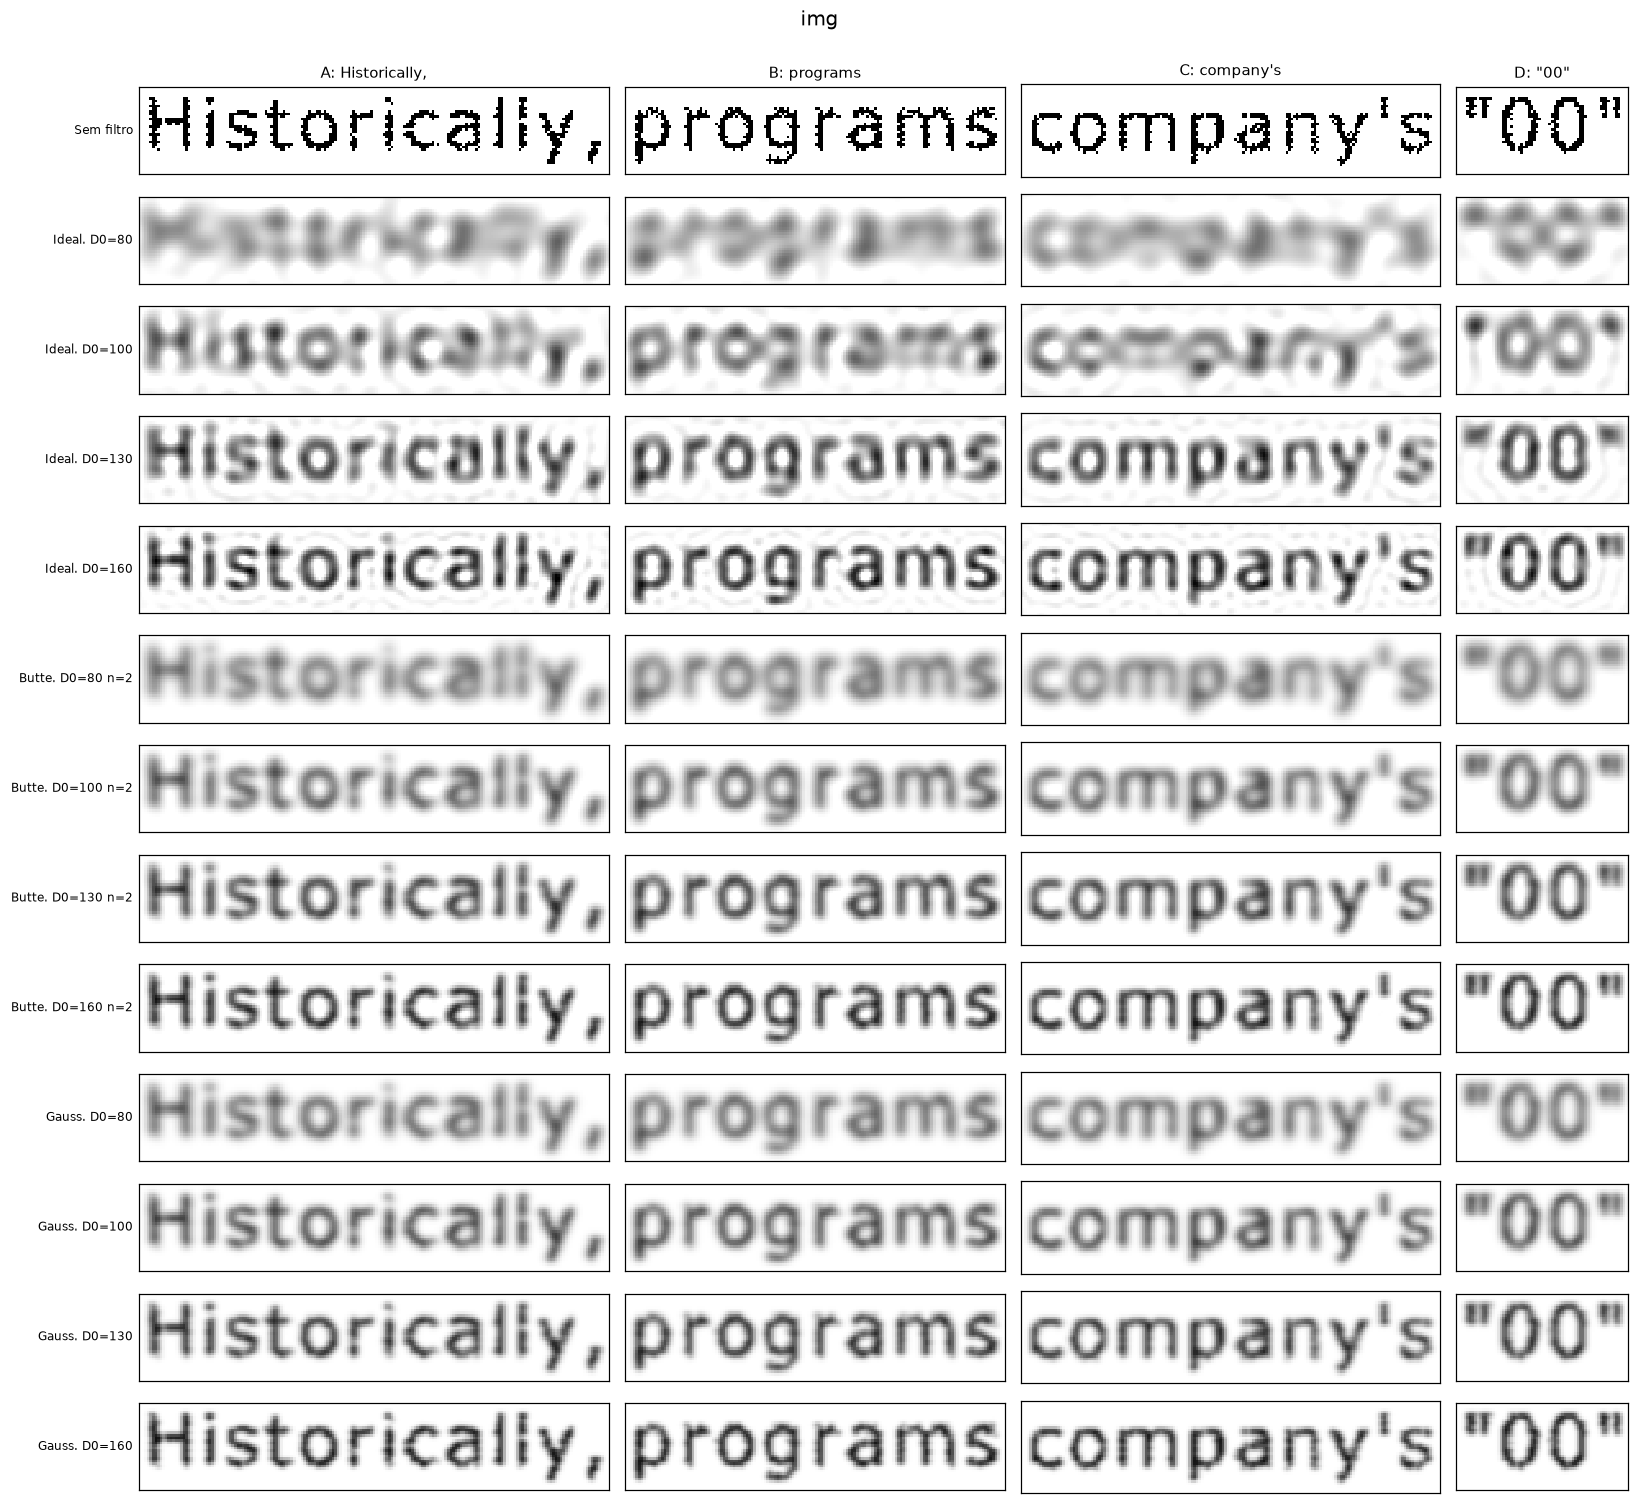

In [19]:
CONFIGS_VIS = [('Sem filtro', 0, 0)] + [(nome, D0, 2) for nome in FILTROS.values() for D0 in (80, 100, 130, 160)]

def rotulo(cfg):
    filtro, D0, n = cfg
    if D0 == 0:
        return 'Sem filtro'
    return f'{filtro[:5]}. D0={D0}' + (f' n={n}' if filtro == 'Butterworth' else '')

def painel(metodo, nome_fig):
    fig = painel_recortes([(rotulo(cfg), resultados[cfg][metodo]) for cfg in CONFIGS_VIS], titulo=metodo)
    salvar(fig, nome_fig); plt.show()

painel('img', '08_recortes_filtradas')

**Leitura:** o ideal cria anéis claros/escuros ao redor dos traços (ringing), fortes em $D_0$ = 80–100. Butterworth e gaussiano só borram; com $D_0$ = 80 o cinza de letras vizinhas já se encosta.

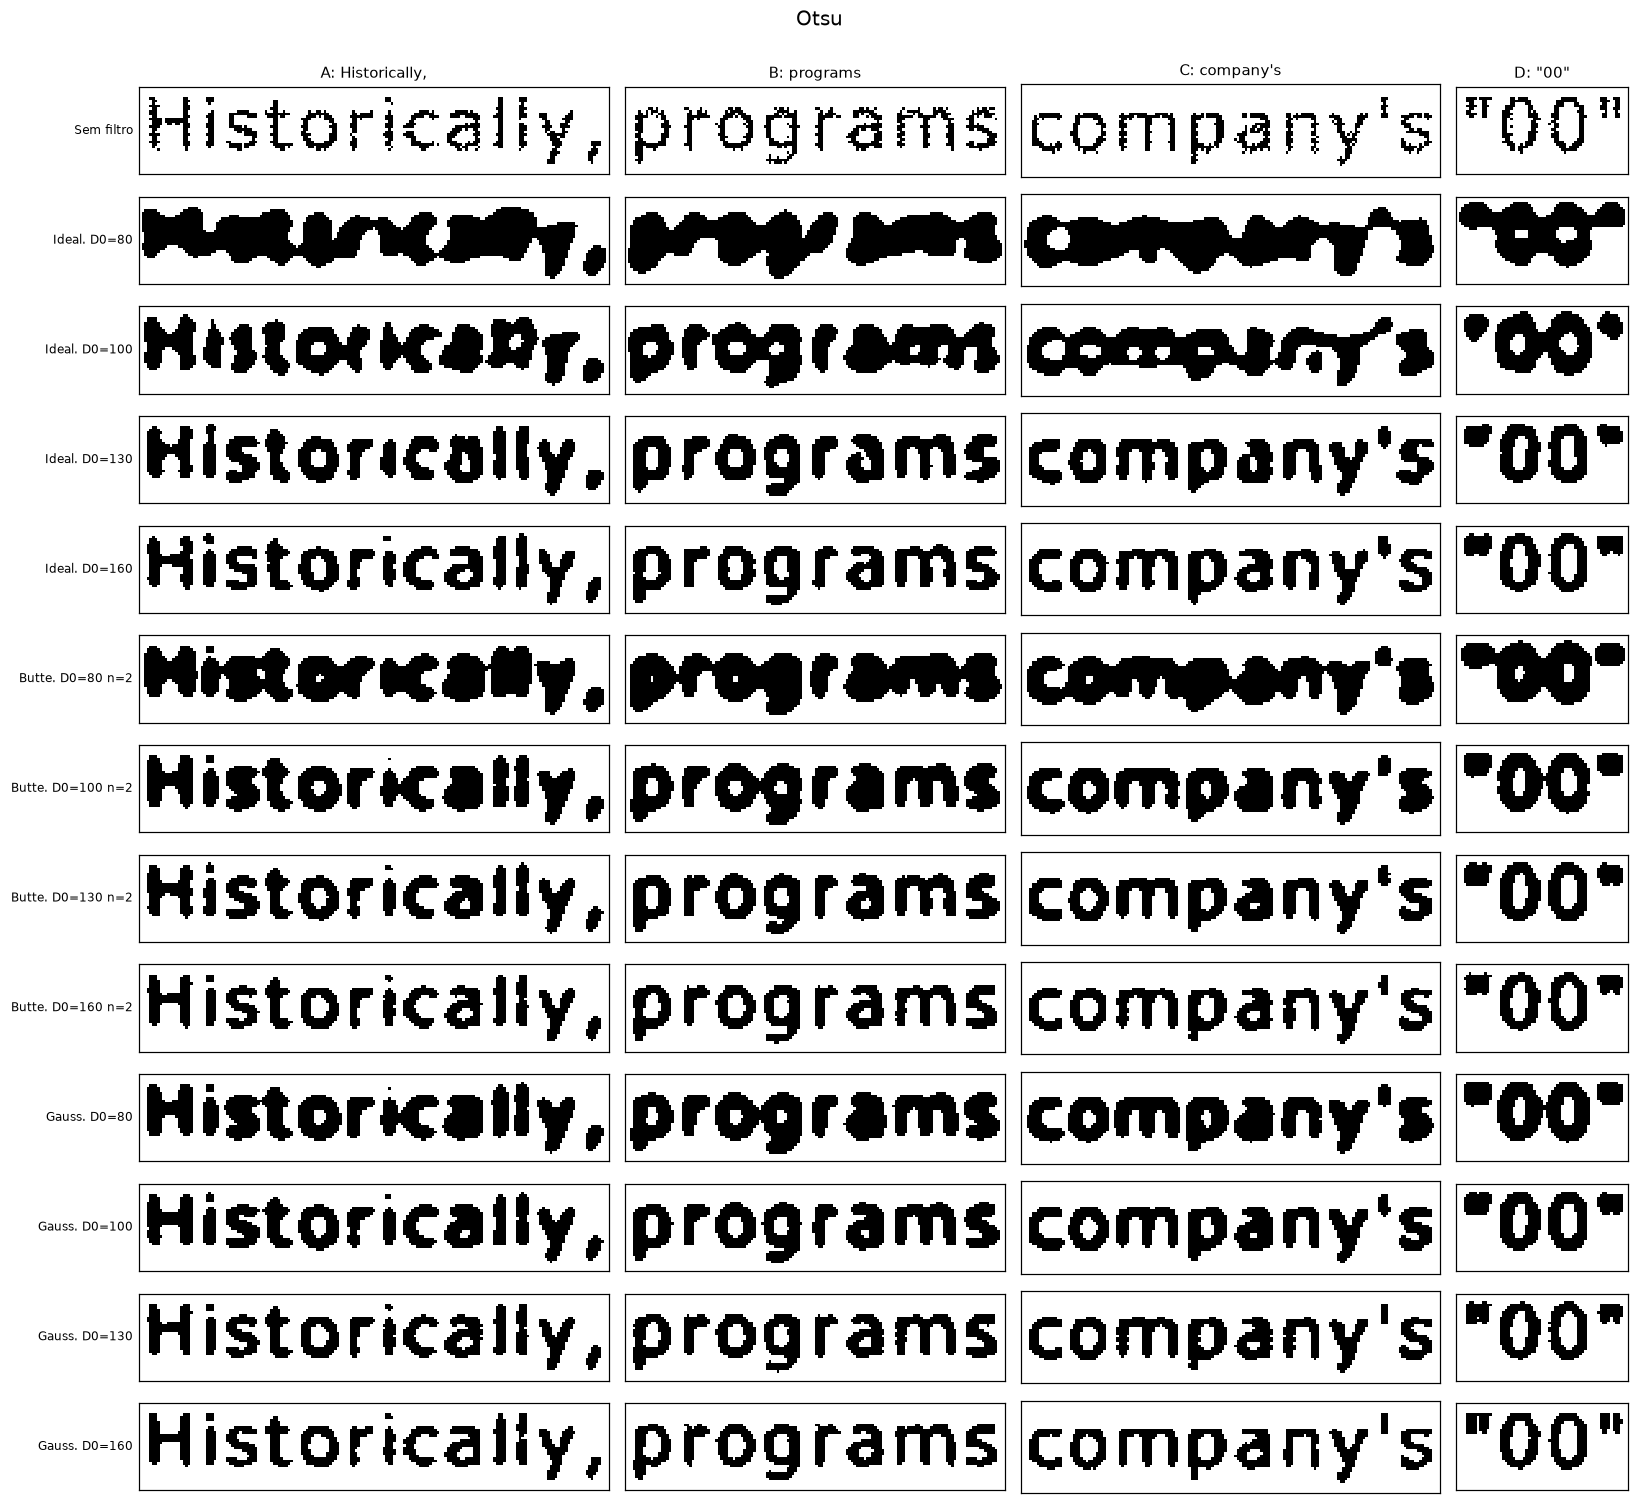

In [20]:
painel('Otsu', '09_recortes_otsu')

**Leitura (Otsu):** com $D_0$ = 80 os três filtros unem letras (ideal 39, Butterworth 46, gaussiano 12 uniões) e fecham o miolo de `o`, `a`, `e`. Em $D_0$ = 100 o ideal ainda une 37 e o Butterworth 11, enquanto o gaussiano já separa todas (64 de 72 buracos). Em $D_0$ = 160 os três dão letras inteiras, sem furos e com 70–71 buracos.

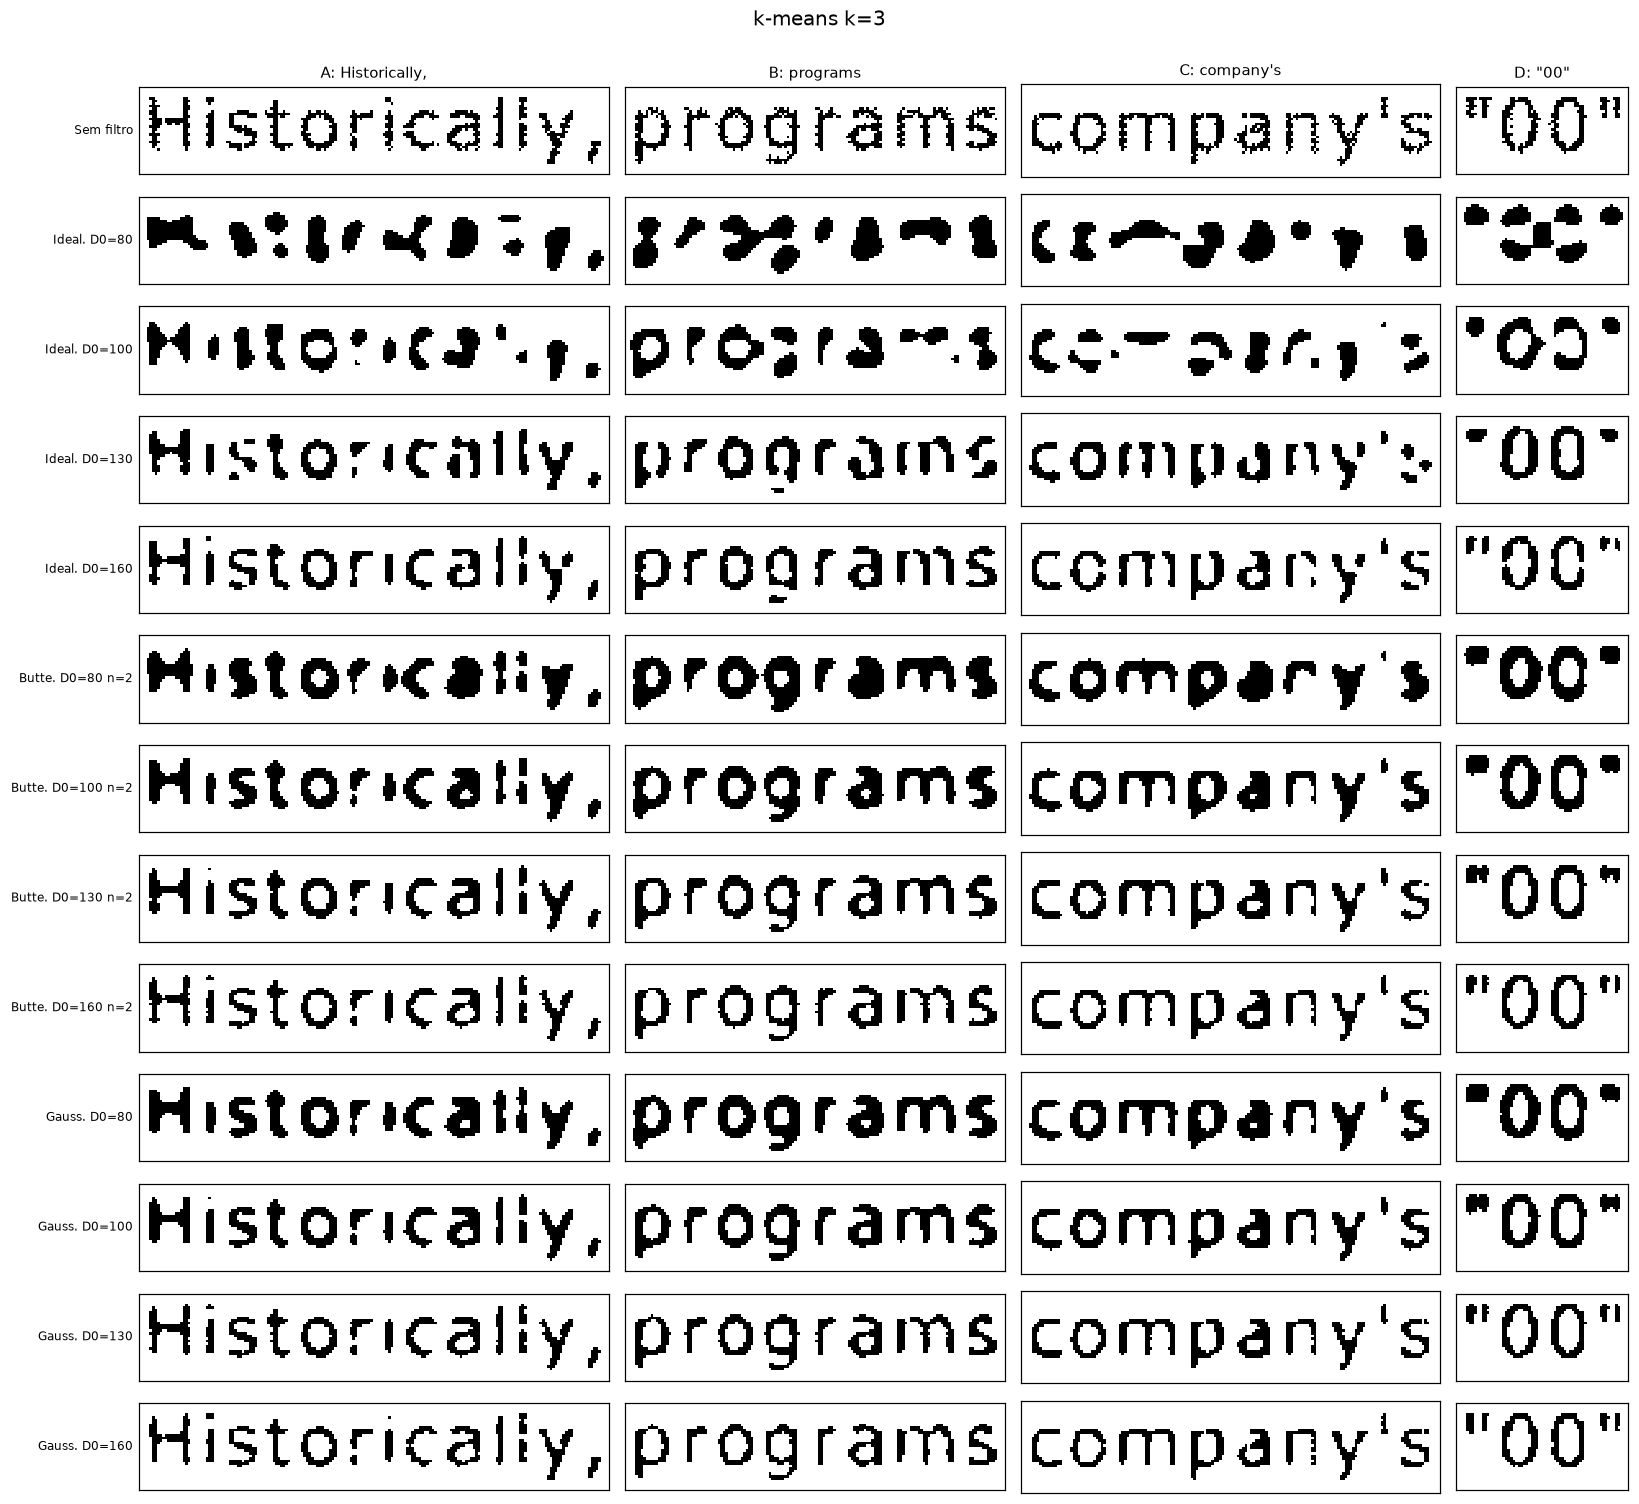

In [21]:
painel('k-means k=3', '10_recortes_kmeans_k3')

**Leitura (k-means k=3):** o traço fica fino, mas o preço é apagamento: com o ideal em 80–100 as letras viram fragmentos, e em quase todas as configurações somem os pingos do `i` ("Hıstorıcally").

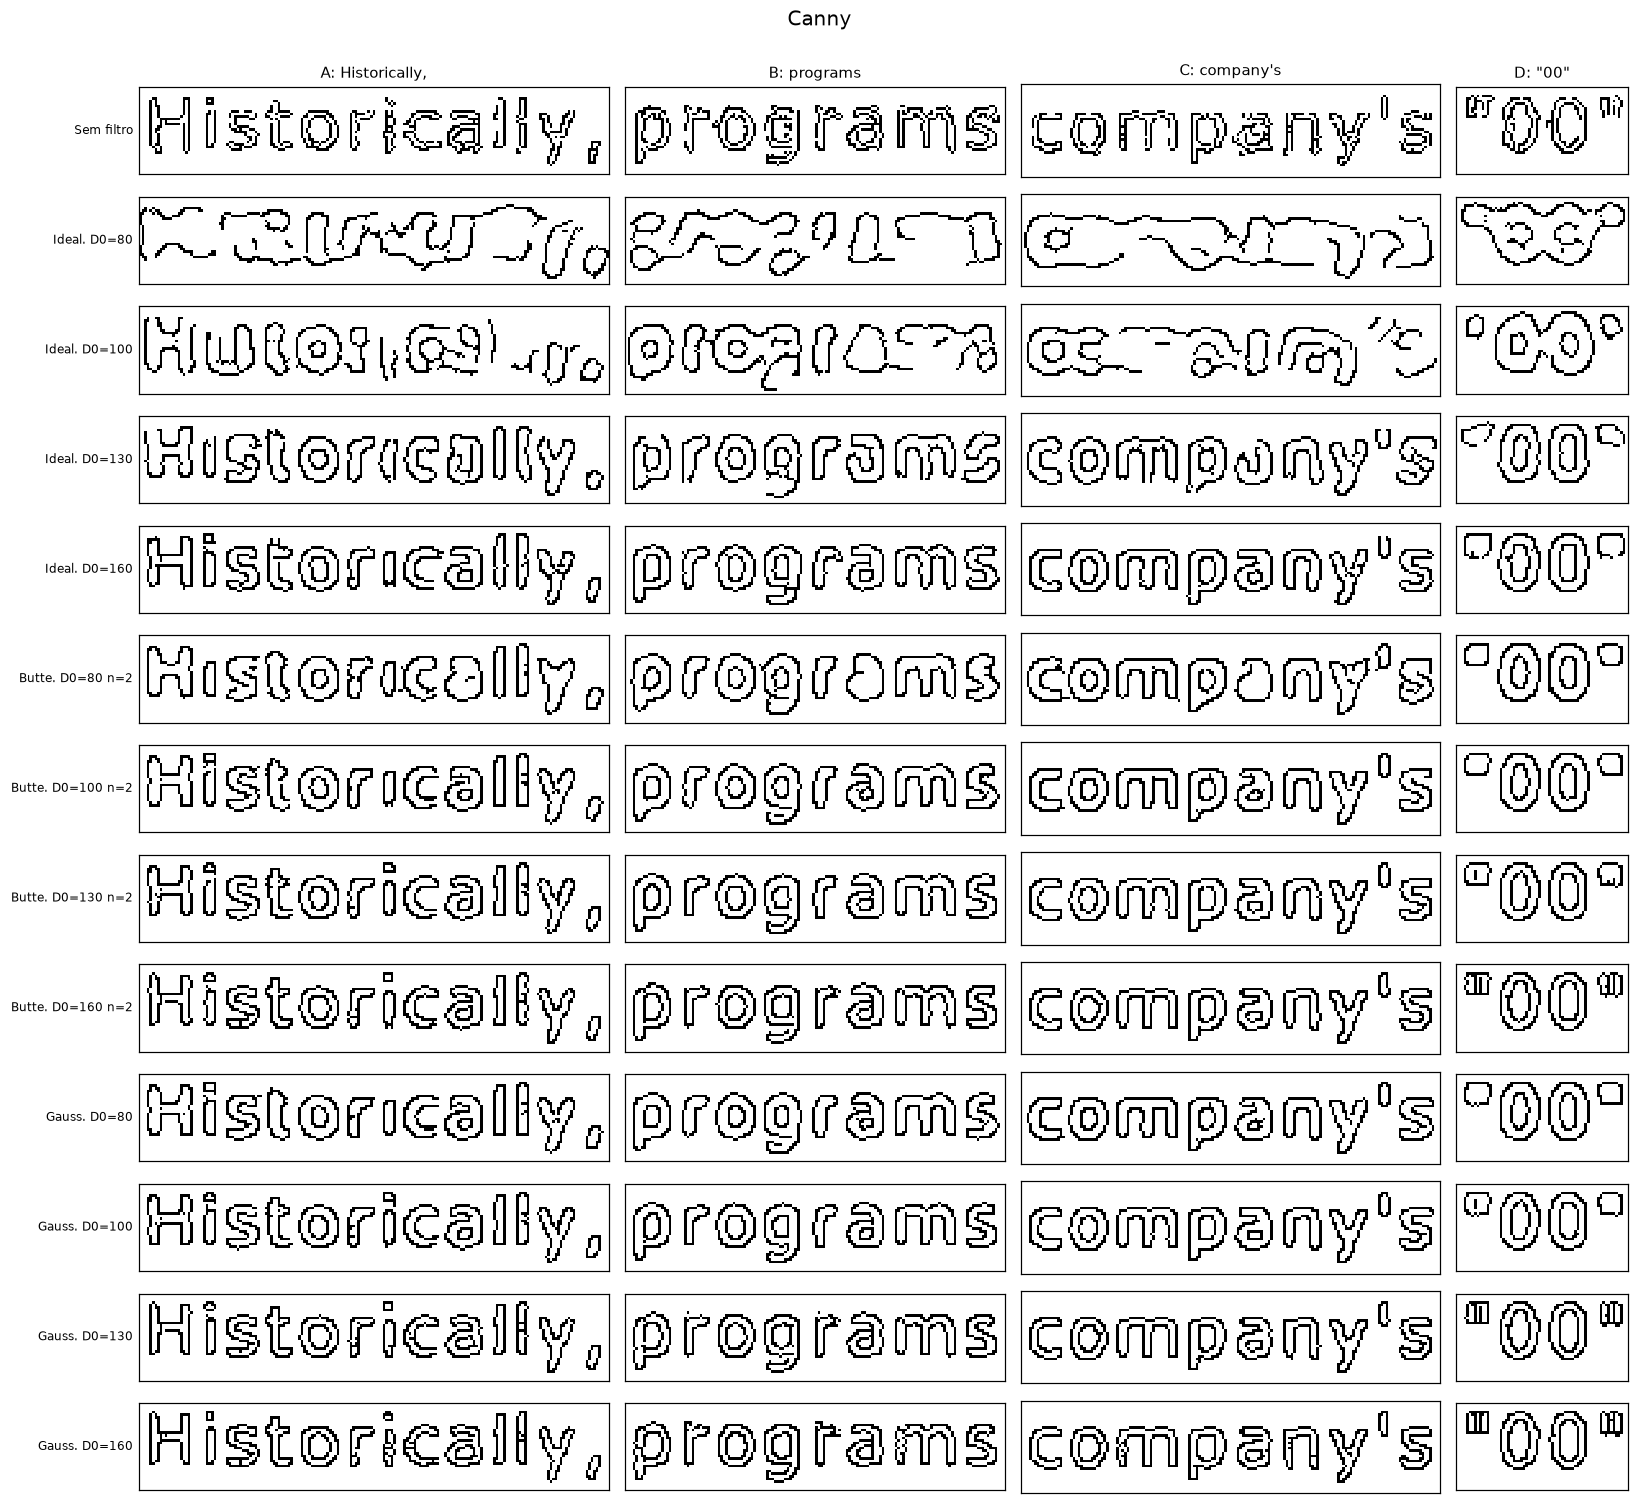

In [22]:
painel('Canny', '11_recortes_canny')

**Leitura (Canny):** sem filtro, cada falha vira um pequeno contorno extra. Com o ideal em 80–100 os contornos de letras vizinhas se fundem; com Butterworth 80 e ideal 130 somem pingos do `i`. Gaussiano e Butterworth em 100–160 dão contornos quase todos fechados, um por letra.

k-means k=2 não tem painel próprio: é praticamente igual ao Otsu.

In [23]:
difs = [(cfg, (r['Otsu'] != r['k-means k=2']).sum()) for cfg, r in resultados.items()]
print('pixels diferentes entre Otsu e k-means k=2 (máximo entre todas as configurações):',
      max(d for _, d in difs), 'de', M * N)

pixels diferentes entre Otsu e k-means k=2 (máximo entre todas as configurações): 677 de 223652


## 8. Quando a filtragem piora

Melhor configuração (escore): ('Gaussiano', 160, 2) Otsu escore = 0.025


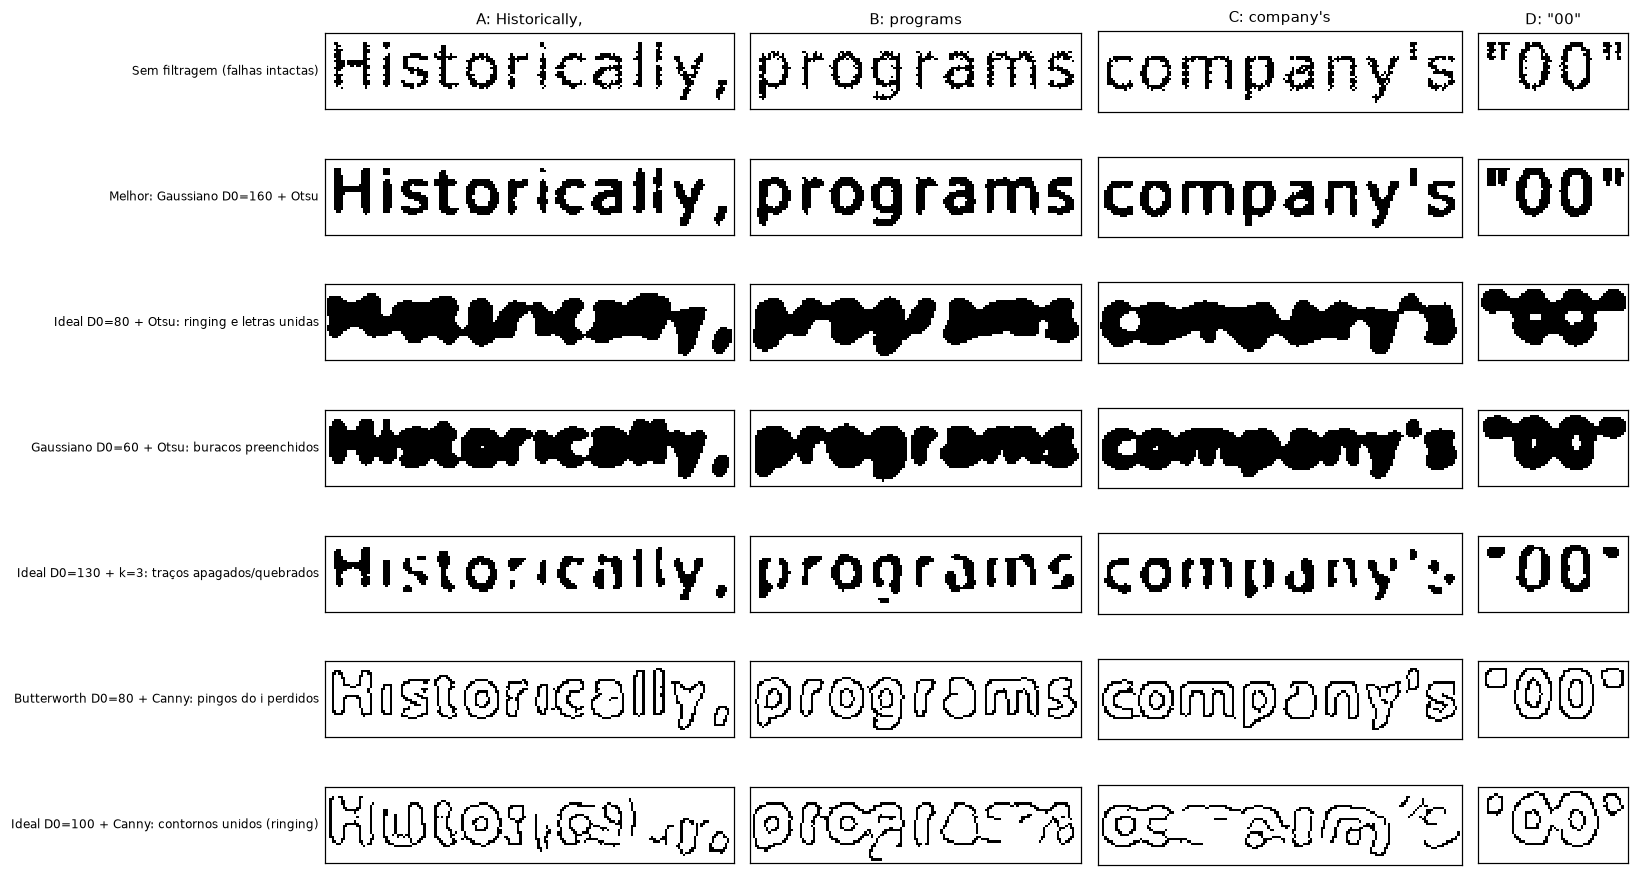

,componentes,buracos_legit,furos_falha,unioes,preservacao_%,acrescimo_%,espessura_px
caso,,,,,,,
Sem filtragem (falhas intactas),265,43,165,0,100.000,0.000,2
Melhor: Gaussiano D0=160 + Otsu,204,71,0,0,99.401,48.330,4
Ideal D0=80 + Otsu: ringing e letras unidas,61,20,2,39,96.086,196.017,10
Gaussiano D0=60 + Otsu: buracos preenchidos,53,25,5,36,99.679,194.189,7
Ideal D0=130 + k=3: traços apagados/quebrados,294,17,0,0,76.963,30.808,4


In [24]:
ranking = df_mask[df_mask.filtro != 'Sem filtro'].sort_values('escore')
melhor = ranking.iloc[0]
cfg_melhor = (melhor.filtro, int(melhor.D0), int(melhor.n))
print('Melhor configuração (escore):', cfg_melhor, melhor.metodo, f'escore = {melhor.escore:.3f}')

casos = [
    ('Sem filtragem (falhas intactas)',               ('Sem filtro', 0, 0), 'Otsu'),
    (f'Melhor: {melhor.filtro} D0={int(melhor.D0)} + {melhor.metodo}', cfg_melhor, melhor.metodo),
    ('Ideal D0=80 + Otsu: ringing e letras unidas',   ('Ideal', 80, 2), 'Otsu'),
    ('Gaussiano D0=60 + Otsu: buracos preenchidos',   ('Gaussiano', 60, 2), 'Otsu'),
    ('Ideal D0=130 + k=3: traços apagados/quebrados', ('Ideal', 130, 2), 'k-means k=3'),
    ('Butterworth D0=80 + Canny: pingos do i perdidos', ('Butterworth', 80, 2), 'Canny'),
    ('Ideal D0=100 + Canny: contornos unidos (ringing)', ('Ideal', 100, 2), 'Canny'),
]
fig = painel_recortes([(t, resultados[c][m]) for t, c, m in casos], altura_linha=1.2)
salvar(fig, '12_melhora_x_piora'); plt.show()

casos_tab = pd.DataFrame([{'caso': t, **metricas_mascara(resultados[c][m], T0)} for t, c, m in casos if m != 'Canny'])
display(casos_tab.set_index('caso'))

**Leitura:** a mesma filtragem que fecha as falhas, se exagerada ($D_0$ pequeno) ou com ringing (ideal), une letras, preenche buracos ou apaga traços. A melhor configuração fica na faixa intermediária.

## 9. Melhor combinação

In [25]:
colunas = ['filtro', 'D0', 'n', 'metodo', 'componentes', 'buracos_legit', 'furos_falha', 'unioes',
           'preservacao_%', 'acrescimo_%', 'espessura_px', 'escore']
print(f'Esperado: componentes = {C_ESP}, buracos_legit = {H_ESP}, furos_falha = 0, unioes = 0, preservacao = 100%')
display(ranking[colunas].head(10).reset_index(drop=True))

Esperado: componentes = 205, buracos_legit = 72, furos_falha = 0, unioes = 0, preservacao = 100%


,filtro,D0,n,metodo,componentes,buracos_legit,furos_falha,unioes,preservacao_%,acrescimo_%,espessura_px,escore
0,Gaussiano,160,2,Otsu,204,71,0,0,99.401,48.330,4,0.025
1,Gaussiano,160,2,k-means k=2,204,71,0,0,99.401,48.330,4,0.025
2,Butterworth,200,2,k-means k=2,206,71,0,0,99.105,38.441,4,0.028
3,Butterworth,200,2,Otsu,206,71,0,0,99.105,38.441,4,0.028
4,Butterworth,160,2,Otsu,201,71,0,0,99.338,63.917,4,0.040
5,Butterworth,160,2,k-means k=2,201,71,0,0,99.313,62.379,4,0.040
6,Gaussiano,130,2,k-means k=2,201,71,1,0,99.332,65.965,4,0.046
7,Gaussiano,130,2,Otsu,201,71,1,0,99.332,65.965,4,0.046
8,Ideal,160,2,Otsu,200,70,0,0,98.393,72.539,5,0.068
9,Ideal,160,2,k-means k=2,200,70,0,0,98.393,72.539,5,0.068


In [26]:
print('Melhor por método:')
display(ranking.loc[ranking.groupby('metodo').escore.idxmin(), colunas].reset_index(drop=True))
print('Melhor por filtro:')
display(ranking.loc[ranking.groupby('filtro').escore.idxmin(), colunas].reset_index(drop=True))
print(f'Canny (esperado: ~{CONTORNOS_ESP} contornos, 0 pontas soltas; sem filtragem: escore '
      f'{df_canny[df_canny.filtro == "Sem filtro"].escore.iloc[0]:.3f}):')
ranking_canny = df_canny[df_canny.filtro != 'Sem filtro'].sort_values('escore')
display(ranking_canny.head(5).reset_index(drop=True))

Melhor por método:


,filtro,D0,n,metodo,componentes,buracos_legit,furos_falha,unioes,preservacao_%,acrescimo_%,espessura_px,escore
0,Gaussiano,160,2,Otsu,204,71,0,0,99.401,48.330,4,0.025
1,Gaussiano,160,2,k-means k=2,204,71,0,0,99.401,48.330,4,0.025
2,Gaussiano,100,2,k-means k=3,202,69,0,0,90.968,32.926,3,0.147


Melhor por filtro:


,filtro,D0,n,metodo,componentes,buracos_legit,furos_falha,unioes,preservacao_%,acrescimo_%,espessura_px,escore
0,Butterworth,200,2,k-means k=2,206,71,0,0,99.105,38.441,4,0.028
1,Gaussiano,160,2,Otsu,204,71,0,0,99.401,48.330,4,0.025
2,Ideal,160,2,Otsu,200,70,0,0,98.393,72.539,5,0.068


Canny (esperado: ~277 contornos, 0 pontas soltas; sem filtragem: escore 1.466):


,filtro,D0,n,metodo,segmentos,pontas_soltas,pixels_borda,escore
0,Gaussiano,100,2,Canny,275,103,14709,0.142
1,Butterworth,130,2,Canny,271,103,14725,0.157
2,Gaussiano,80,2,Canny,278,136,14507,0.182
3,Butterworth,160,2,Canny,262,101,14892,0.187
4,Gaussiano,130,2,Canny,264,111,14920,0.192


### Sensibilidade do escore

O escore não pune o **engrossamento** do traço. Abaixo, o mesmo ranking somando o acréscimo de pixels ($\text{acréscimo}/100$) ou o erro de espessura ($|e-2|/2$).

In [27]:
sens = ranking.assign(**{'escore + acréscimo': ranking.escore + ranking['acrescimo_%'] / 100,
                         'escore + espessura': ranking.escore + abs(ranking.espessura_px - 2) / 2})
for col in ['escore', 'escore + acréscimo', 'escore + espessura']:
    top = sens.sort_values(col).iloc[0]
    print(f'{col:18s} -> {top.filtro} D0={int(top.D0)} + {top.metodo} ({top[col]:.3f}, traço de {top.espessura_px} px)')
g_otsu = sens[(sens.filtro == 'Gaussiano') & (sens.metodo == 'Otsu')].set_index('D0').sort_index()
display(g_otsu[['componentes', 'buracos_legit', 'furos_falha', 'espessura_px', 'acrescimo_%',
                'escore', 'escore + acréscimo', 'escore + espessura']])

escore             -> Gaussiano D0=160 + Otsu (0.025, traço de 4 px)
escore + acréscimo -> Gaussiano D0=200 + Otsu (0.344, traço de 3 px)
escore + espessura -> Gaussiano D0=200 + Otsu (0.573, traço de 3 px)


,componentes,buracos_legit,furos_falha,espessura_px,acrescimo_%,escore,escore + acréscimo,escore + espessura
D0,,,,,,,,
60,53,25,5,7,194.189,1.603,3.545,4.103
80,178,38,3,6,129.541,0.685,1.980,2.685
100,197,64,6,5,94.599,0.192,1.138,1.692
130,201,71,1,4,65.965,0.046,0.706,1.046
160,204,71,0,4,48.330,0.025,0.508,1.025
200,208,69,2,3,27.178,0.073,0.344,0.573


### Resultado final na imagem inteira

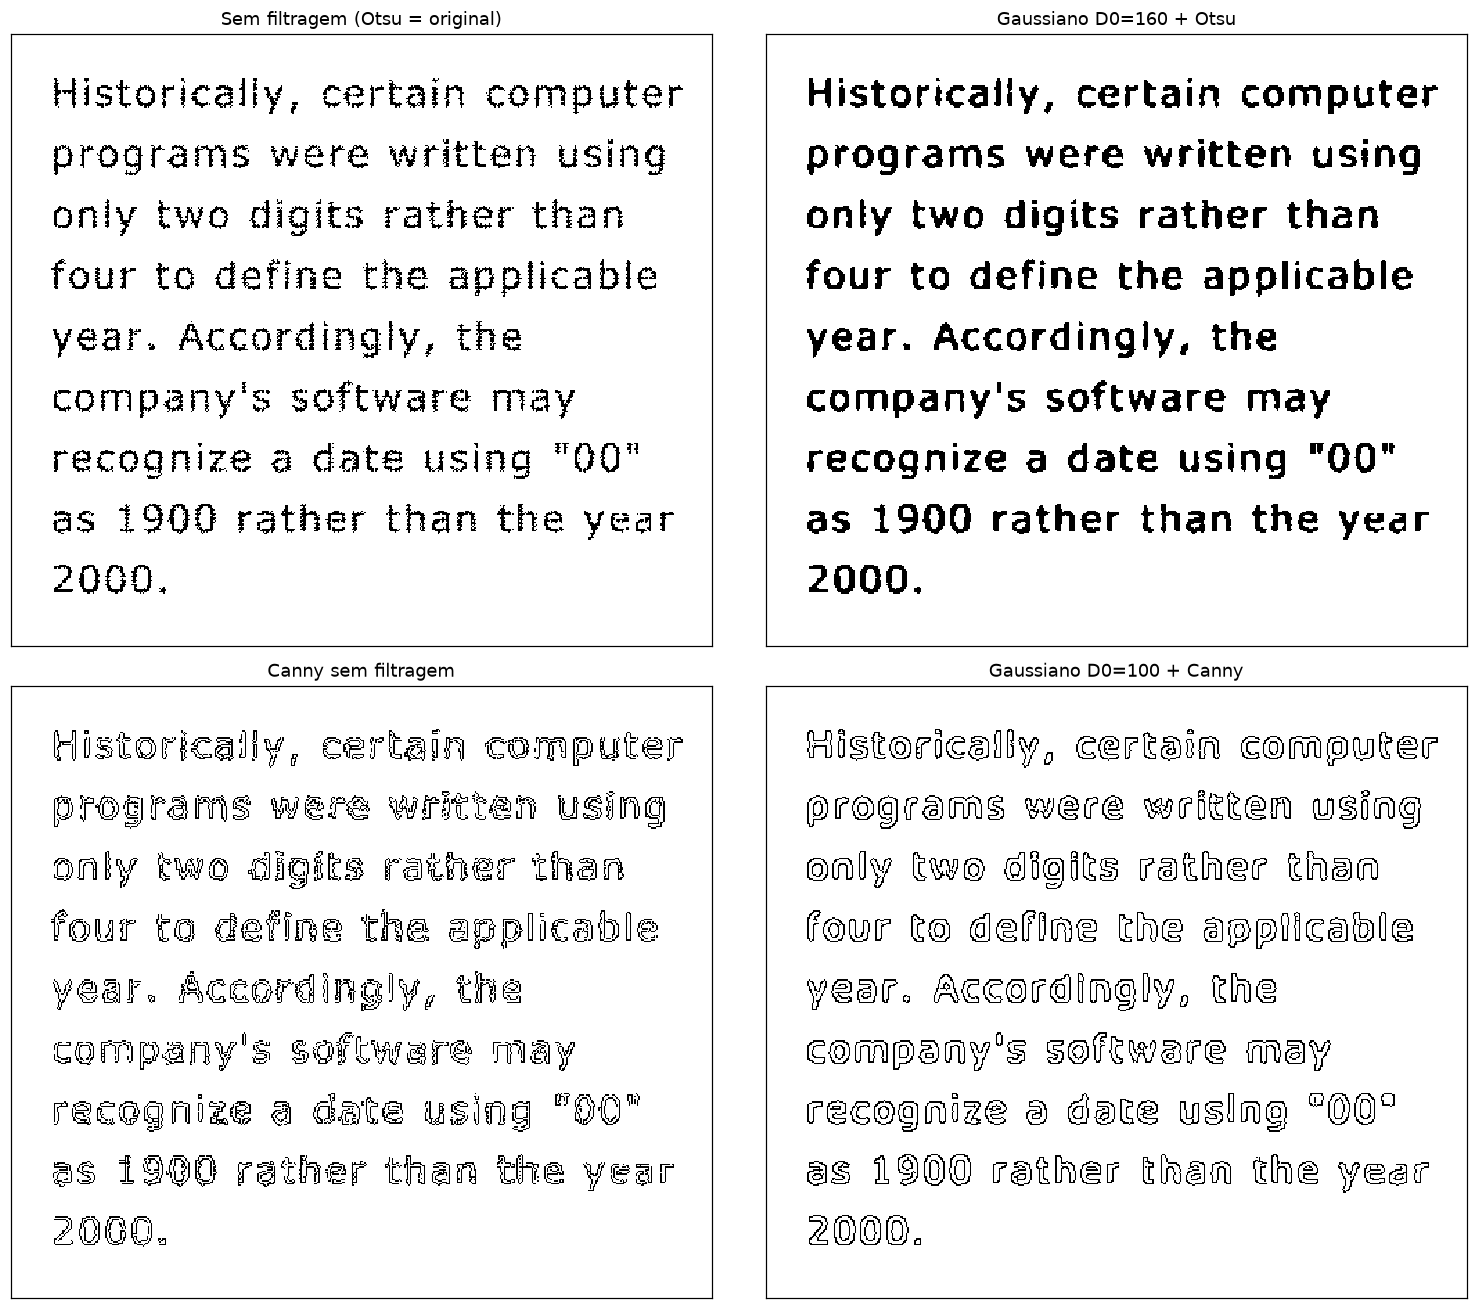

In [28]:
melhor_canny = ranking_canny.iloc[0]
cfg_canny = (melhor_canny.filtro, int(melhor_canny.D0), int(melhor_canny.n))
fig, ax = plt.subplots(2, 2, figsize=(14, 12))
mostrar(ax[0, 0], T0); ax[0, 0].set_title('Sem filtragem (Otsu = original)')
mostrar(ax[0, 1], resultados[cfg_melhor][melhor.metodo])
ax[0, 1].set_title(f'{melhor.filtro} D0={int(melhor.D0)} + {melhor.metodo}')
mostrar(ax[1, 0], resultados[('Sem filtro', 0, 0)]['Canny']); ax[1, 0].set_title('Canny sem filtragem')
mostrar(ax[1, 1], resultados[cfg_canny]['Canny'])
ax[1, 1].set_title(f'{melhor_canny.filtro} D0={int(melhor_canny.D0)} + Canny')
plt.tight_layout(); salvar(fig, '13_melhor_resultado'); plt.show()

## Conclusões

A discussão completa, com os gráficos das métricas, está no relatório.

* **Sem filtragem** nenhum método corrige as falhas: a imagem já é binária (165 furos; Canny com 763 pontas soltas).
* **A filtragem melhora** numa faixa intermediária de $D_0$ e com filtro sem ringing: gaussiano $D_0$ = 130–200 + Otsu zera ou quase zera os furos, sem unir letras.
* **A filtragem piora** com $D_0$ pequeno (letras unidas, buracos preenchidos, pingos apagados), com o filtro ideal ou Butterworth de ordem alta (ringing) e com $D_0$ grande demais (as falhas voltam).
* **Otsu e k-means k=2** são equivalentes; **k=3** afina o traço, mas apaga.

**Melhor combinação: gaussiano, $D_0$ = 160, + Otsu** — 204 componentes, 71 buracos, 0 furos, 0 uniões, 99,4% do texto preservado (escore 0,025). Penalizando o engrossamento, o melhor passa a $D_0$ = 200, então a faixa recomendada é 160–200. Para bordas: gaussiano $D_0$ = 100 + Canny.